In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (Input, Dense, Embedding, Flatten, Concatenate, GRU, Lambda)
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [14]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [15]:
symbols = ["AAPL","AIG","BAC","GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(
        f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx",
        parse_dates=[0]
    )
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Δημιουργία Trend
    df["Trend"] = df.iloc[:,3].shift(-30)/df.iloc[:,3]
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

# Features και target
X_trend_num = dataset.iloc[:, [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 19, 20, 21]]
X_trend_sym = dataset["Symbol_enc"]
y_trend = np.log1p(dataset["Trend"])

In [16]:
print(X_trend_num)
print(X_trend_sym)
print(y_trend)

                 Open       High        Low      Close      RSI      SMA  \
Date                                                                       
2019-01-02  36.985080  37.930661  36.827482  37.708591  38.1140  44.1389   
2019-01-03  34.379965  34.795449  33.907176  33.952545  27.9036  43.7742   
2019-01-04  34.511295  35.471204  34.336985  35.401955  35.1259  43.4322   
2019-01-07  35.507026  35.538069  34.838433  35.323162  34.9211  43.0787   
2019-01-08  35.712380  36.252032  35.464047  35.996532  38.2354  42.7750   
...               ...        ...        ...        ...      ...      ...   
2024-11-11   6.450000   7.700000   6.383000   7.550000  58.1338   6.5396   
2024-11-12   7.370000   7.700000   6.710000   7.060000  52.6522   6.5576   
2024-11-13   7.340000   8.190000   7.070000   7.080000  52.8477   6.5734   
2024-11-14   7.250000   7.441000   6.495000   6.580000  47.5622   6.5842   
2024-11-15   6.600000   6.945000   6.590000   6.770000  49.6240   6.6028   

           

In [17]:
# GRU parameters
TIMESTEPS = 10

def create_sequences(X_trend_num, X_trend_sym, y_trend, timesteps):
    Xn, Xs, yt = [], [], []

    for sym in np.unique(X_trend_sym):
        mask = (X_trend_sym == sym)

        X_trend_sym_df = X_trend_num.loc[mask].reset_index(drop=True)
        y_trend_sym = y_trend.loc[mask].reset_index(drop=True)

        for i in range(timesteps, len(X_trend_sym_df)):
            Xn.append(X_trend_sym_df.iloc[i-timesteps:i].values)
            Xs.append(sym)
            yt.append(y_trend_sym.iloc[i])

    return np.array(Xn), np.array(Xs), np.array(yt)

In [18]:
test_size = 0.2
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_trend_num.loc[X_trend_num.index.isin(train_dates)]
X_sym_train = X_trend_sym.loc[X_trend_sym.index.isin(train_dates)]
y_train = y_trend.loc[y_trend.index.isin(train_dates)]

X_num_test = X_trend_num.loc[X_trend_num.index.isin(test_dates)]
X_sym_test = X_trend_sym.loc[X_trend_sym.index.isin(test_dates)]
y_test = y_trend.loc[y_trend.index.isin(test_dates)]

train_dates_sorted = X_num_train.index.unique().sort_values()
val_len = int(len(train_dates_sorted) * 0.2)

train_dates_final = train_dates_sorted[:-val_len]
val_dates = train_dates_sorted[-val_len:]

X_num_train_final = X_trend_num.loc[X_trend_num.index.isin(train_dates_final)]
X_sym_train_final = X_trend_sym.loc[X_trend_sym.index.isin(train_dates_final)]
y_train_final = y_trend.loc[y_trend.index.isin(train_dates_final)]

X_num_val = X_trend_num.loc[X_trend_num.index.isin(val_dates)]
X_sym_val = X_trend_sym.loc[X_trend_sym.index.isin(val_dates)]
y_val = y_trend.loc[y_trend.index.isin(val_dates)]

In [19]:
# Feature scaling
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [20]:
# Sequences
Xn_train, Xs_train, y_train_seq = create_sequences( pd.DataFrame(X_num_train_final), X_sym_train_final.reset_index(drop=True), y_train_final.reset_index(drop=True), TIMESTEPS )
Xn_val, Xs_val, y_val_seq = create_sequences( pd.DataFrame(X_num_val), X_sym_val.reset_index(drop=True), y_val.reset_index(drop=True), TIMESTEPS )
Xn_test, Xs_test, y_test_seq = create_sequences( pd.DataFrame(X_num_test), X_sym_test.reset_index(drop=True), y_test.reset_index(drop=True), TIMESTEPS )

In [21]:
# Νευρωνικό Δίκτυο
num_input = Input(shape=(TIMESTEPS, Xn_train.shape[2]), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

sym_embed = Embedding(num_symbols, 4)(sym_input)
sym_embed = Flatten()(sym_embed)

time_positions = Lambda(lambda z: tf.tile(tf.reshape(tf.linspace(0.0, 1.0, tf.shape(z)[1]), (1, -1, 1)), [tf.shape(z)[0], 1, 1]))(num_input)

sequence_with_time = Concatenate(axis=-1)([num_input, time_positions])

x = GRU(16)(sequence_with_time)
x = Concatenate()([x, sym_embed])
x = Dense(8, activation="relu")(x)
x = Dense(4, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model([num_input, sym_input], output)
model.compile(optimizer=Adam(0.0005), loss="mean_squared_error", metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, min_delta=1e-4, restore_best_weights=True )
history=model.fit([Xn_train, Xs_train],y_train_seq, validation_data=([Xn_val, Xs_val], y_val_seq), epochs=1000, batch_size=32, callbacks=[early_stopping])

Epoch 1/1000
329/329 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.1830 - mae: 0.3400 - mape: 48.2217 - rmse: 0.4278 - val_loss: 0.0761 - val_mae: 0.2427 - val_mape: 34.8393 - val_rmse: 0.2758
Epoch 2/1000
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0136 - mae: 0.0821 - mape: 11.8444 - rmse: 0.1167 - val_loss: 0.0164 - val_mae: 0.1057 - val_mape: 15.1317 - val_rmse: 0.1281
Epoch 3/1000
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0088 - mae: 0.0646 - mape: 9.3690 - rmse: 0.0938 - val_loss: 0.0131 - val_mae: 0.0954 - val_mape: 13.7814 - val_rmse: 0.1144
Epoch 4/1000
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0077 - mae: 0.0604 - mape: 8.7857 - rmse: 0.0879 - val_loss: 0.0133 - val_mae: 0.0962 - val_mape: 13.8792 - val_rmse: 0.1152
Epoch 5/1000
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0072 - mae: 0.0580 - mape: 8.4411 - rmse: 0.0847 - val_loss: 0.0129 - val_mae: 0.0939 - val_mape: 13.6079 - val_rmse: 0.1135
Epoch 6/1000
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

In [22]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([Xn_test,Xs_test], y_test_seq)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0141 - mae: 0.0986 - mape: 14.6759 - rmse: 0.1186
Test Loss (MSE): 0.01406160555779934, Test MAE: 0.09855043143033981


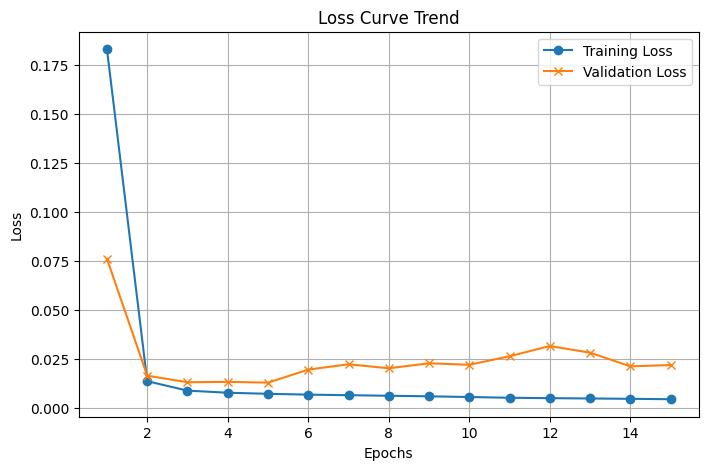

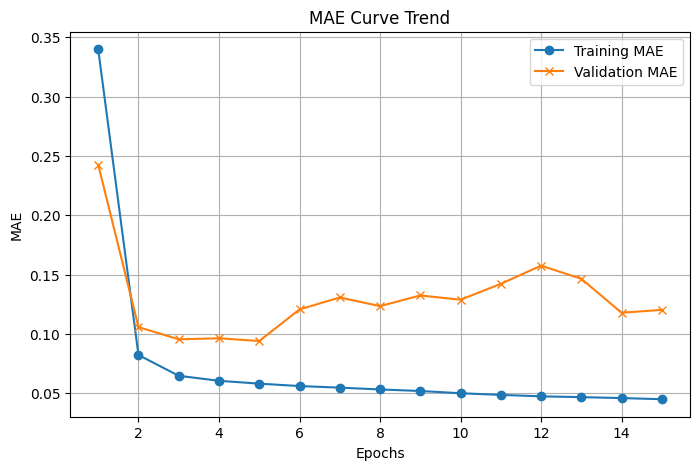

In [23]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Trend')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Trend')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
y_pred = model.predict([Xn_test,Xs_test])

y_test_real = np.expm1(y_test_seq).reshape(-1)
y_pred_real = np.expm1(y_pred).reshape(-1)


mae  = mean_absolute_error((y_test_real), (y_pred_real))
rmse = np.sqrt(mean_squared_error((y_test_real), (y_pred_real)))
mape = np.mean(np.abs(((y_test_real) - (y_pred_real)) / (y_test_real))) * 100
r2   = r2_score((y_test_real), (y_pred_real))
relative_mae = mae / np.mean(y_test_real) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE: {relative_mae:.2f}%")

91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
MAE  : 0.19
RMSE : 0.23
MAPE : 20.16%
R²   : -1.987
Relative MAE: 19.44%
